In [1]:
# Cell 1 — imports the data files - ISLP 3
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
from statsmodels.api import OLS
import statsmodels.api as sm
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import os

for folder in ["data", "figs", "tabs"]:
    os.makedirs(folder, exist_ok=True)

def save_latex_table(filename, caption, label, col_spec, header, rows, resizebox=None):
    """Write a booktabs-style LaTeX table to tabs/<filename>."""
    lines = [r"\begin{table}[H]", r"\centering",
             f"\\caption{{{caption}}}", f"\\label{{{label}}}"]
    if resizebox:
        lines.append(f"\\resizebox{{{resizebox}}}{{!}}{{%")
    lines.append(f"\\begin{{tabular}}{{{col_spec}}}")
    lines.append(r"\toprule")
    lines.append(header + r" \\")
    lines.append(r"\midrule")
    lines.extend(row + r" \\" for row in rows)
    lines.append(r"\bottomrule")
    lines.append(r"\end{tabular}")
    if resizebox:
        lines.append("}")
    lines.append(r"\end{table}")
    with open(f"tabs/{filename}", "w") as f:
        f.write("\n".join(lines) + "\n")
    print(f"Saved: tabs/{filename}")

In [ ]:
# Cell 2 — Data Load
raw = pd.read_stata("data/Main_data.dta", convert_categoricals=False)

first = ["mask", "county", "type_dummy", "year", "unit", "age", "female", "social_science",
         "college_4", "parent_college", "stem", "village_work", "risk_averse",
         "party_member", "local"]
d = raw.groupby("cgvo_id").agg({"cgvo_relative_performance": "mean",
                                **{c: "first" for c in first}}).reset_index()
d = d.rename(columns={"cgvo_relative_performance": "perf", "type_dummy": "cgcs_type",
                      "social_science": "socsci", "college_4": "college4",
                      "parent_college": "parent_coll", "party_member": "party"})

Y_name, TREAT = "perf", "mask"
KEY_COVS = ["age", "female", "socsci", "college4", "parent_coll", "stem",
            "village_work", "risk_averse", "party", "local"]
FE = ["county", "cgcs_type", "year"]

d = d.dropna(subset=[Y_name, TREAT] + FE + KEY_COVS).copy()

flags = []
for c in KEY_COVS:
    if d[c].isna().any():
        d[c + "_miss"] = d[c].isna().astype(int)
        d[c] = d[c].fillna(d[c].median())
        flags.append(c + "_miss")

print(d.shape)

(2743, 17)


C:\Users\unite\AppData\Local\Temp\ipykernel_6664\348099753.py:2: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  raw = pd.read_stata("data/Main_data.dta", convert_categoricals=False)


In [3]:
# Cell 3 — FWL (partialling effect)
FE_dummies = pd.get_dummies(d[FE[0]].astype(str), prefix=FE[0], drop_first=True)
for c in FE[1:]:
    FE_dummies = pd.concat([FE_dummies, pd.get_dummies(d[c].astype(str), prefix=c, drop_first=True)], axis=1)
D_fe = sm.add_constant(FE_dummies.astype(float)).values

def partial_out(v):
    b, *_ = np.linalg.lstsq(D_fe, v, rcond=None)
    return v - D_fe @ b

cols = [TREAT] + KEY_COVS + flags
fe_resid = pd.DataFrame({v: partial_out(d[v].astype(float).values) for v in [Y_name] + cols})

In [4]:
# Cell 4 — design matrix - ISLP 48
D = fe_resid[cols]
X = np.asarray(D)
Y = fe_resid[Y_name].values

In [5]:
# Cell 5 — OLS
Xc = sm.add_constant(D)
ols_fe = OLS(Y, Xc).fit(cov_type="cluster", cov_kwds={"groups": d["unit"].values})
with open("tabs/ols_table.txt", "w") as f:
    f.write(str(ols_fe.summary()))
print(ols_fe.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     5.840
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           2.08e-09
Time:                        17:26:48   Log-Likelihood:                -3242.0
No. Observations:                2743   AIC:                             6508.
Df Residuals:                    2731   BIC:                             6579.
Df Model:                          11                                         
Covariance Type:              cluster                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           3.6e-15      0.016    2.3e-13   

In [ ]:
# Cell 6 — Ridge: coefficient path - ISLP 49
Xs = X - X.mean(0)[None, :]
X_scale = X.std(0)
Xs = Xs / X_scale[None, :]
lambdas = 10**np.linspace(8, -2, 100) / Y.std()
soln_array = skl.ElasticNet.path(Xs, Y, l1_ratio=0., alphas=lambdas)[1]
print(soln_array.shape)

(11, 100)


In [7]:
# Cell 7 — Ridge: ISLP - 51
soln_path = pd.DataFrame(soln_array.T, columns=D.columns, index=-np.log(lambdas))
soln_path.index.name = 'negative log(lambda)'
soln_path.to_csv("tabs/ridge_path_table.csv")

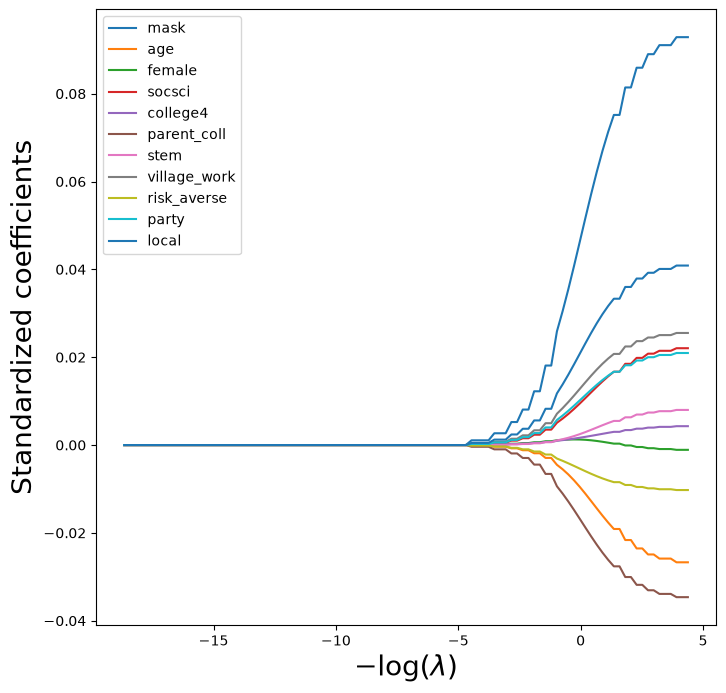

In [8]:
# Cell 8 — Ridge - ISLP 53
path_fig, ax = subplots(figsize=(8, 8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left')

path_fig.savefig("figs/ridge_path_graph.pdf", bbox_inches="tight")


In [9]:
# Cell 9 — Ridge - ISLP 31
K = 5
kfold = skm.KFold(K, random_state=0, shuffle=True)

In [10]:
# Cell 10 — Ridge: - ISLP 61
ridge = skl.ElasticNet(alpha=lambdas[59], l1_ratio=0)
scaler = StandardScaler(with_mean=True, with_std=True)
pipe = Pipeline(steps=[('scaler', scaler), ('ridge', ridge)])
pipe.fit(X, Y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](11,)","[0.,0.,0.,...,0.,0.,0.]"


In [11]:
# Cell 11 — Ridge - ISLP 69
param_grid = {'ridge__alpha': lambdas}
grid = skm.GridSearchCV(pipe, param_grid, cv=kfold, scoring='neg_mean_squared_error')
grid.fit(X, Y)
best_alpha = grid.best_params_['ridge__alpha']
with open("tabs/cell11_best_alpha_table.txt", "w") as f:
    f.write(f"Ridge best alpha (GridSearchCV) = {best_alpha}\n")
print(best_alpha)

0.20428512696917378


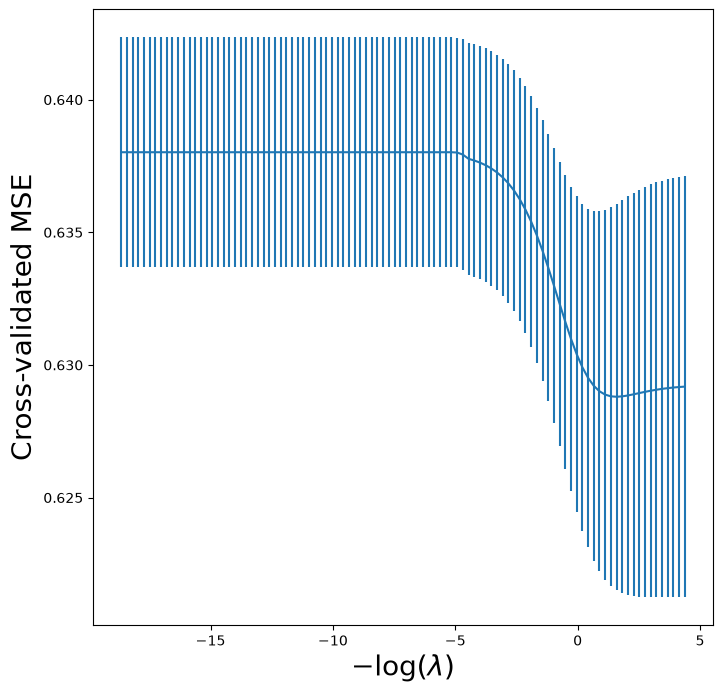

In [12]:
# Cell 12 — Ridge: - ISLP 73 
ridge_fig, ax = subplots(figsize=(8, 8))
ax.errorbar(-np.log(lambdas),
            -grid.cv_results_['mean_test_score'],
            yerr=grid.cv_results_['std_test_score'] / np.sqrt(K))
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20)
ridge_fig.savefig("figs/ridge_cv_mse_graph.pdf", bbox_inches="tight")

In [13]:
# Cell 13 — Ridge: ISLP 79
ridgeCV = skl.ElasticNetCV(alphas=lambdas, l1_ratio=0, cv=kfold)
pipeCV = Pipeline(steps=[('scaler', scaler), ('ridge', ridgeCV)])
pipeCV.fit(X, Y)
tuned_ridge = pipeCV.named_steps['ridge']

Ridge min CV MSE: 0.628785738267496


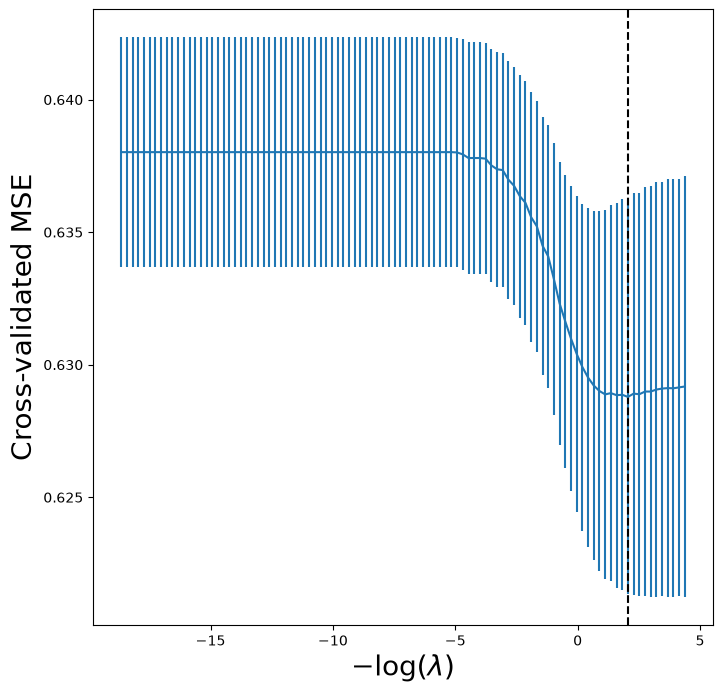

In [14]:
# Cell 14 — Ridge: ISLP 81/83
ridgeCV_fig, ax = subplots(figsize=(8, 8))
ax.errorbar(-np.log(lambdas),
            tuned_ridge.mse_path_.mean(1),
            yerr=tuned_ridge.mse_path_.std(1) / np.sqrt(K))
ax.axvline(-np.log(tuned_ridge.alpha_), c='k', ls='--')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20)
ridgeCV_fig.savefig("figs/ridgeCV_cv_mse_graph.pdf", bbox_inches="tight")
ridge_min_mse = np.min(tuned_ridge.mse_path_.mean(1))
with open("tabs/cell14_ridge_mse_table.txt", "w") as f:
    f.write(f"Ridge min CV MSE = {ridge_min_mse}\n")
    
print("Ridge min CV MSE:", ridge_min_mse)

In [15]:
# Cell 15 — LASSO - ISLP 92
lassoCV = skl.ElasticNetCV(alphas=100, l1_ratio=1, cv=kfold)
pipeCV_l = Pipeline(steps=[('scaler', scaler), ('lasso', lassoCV)])
pipeCV_l.fit(X, Y)
tuned_lasso = pipeCV_l.named_steps['lasso']
with open("tabs/cell15_lasso_alpha_table.txt", "w") as f:
    f.write(f"LASSO best alpha = {tuned_lasso.alpha_}\n")
    
print(tuned_lasso.alpha_)

0.009408292887102704


In [16]:
# Cell 16 — ISLP 93
lambdas_l, soln_array_l = skl.Lasso.path(Xs, Y, l1_ratio=1, n_alphas=100)[:2]
soln_path_l = pd.DataFrame(soln_array_l.T, columns=D.columns, index=-np.log(lambdas_l))

soln_path_l.to_csv("tabs/lasso_path_table.csv")

c:\Users\unite\anaconda3\envs\causalml\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:639: FutureWarning: 'n_alphas' was deprecated in 1.9 and will be removed in 1.11. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.11. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


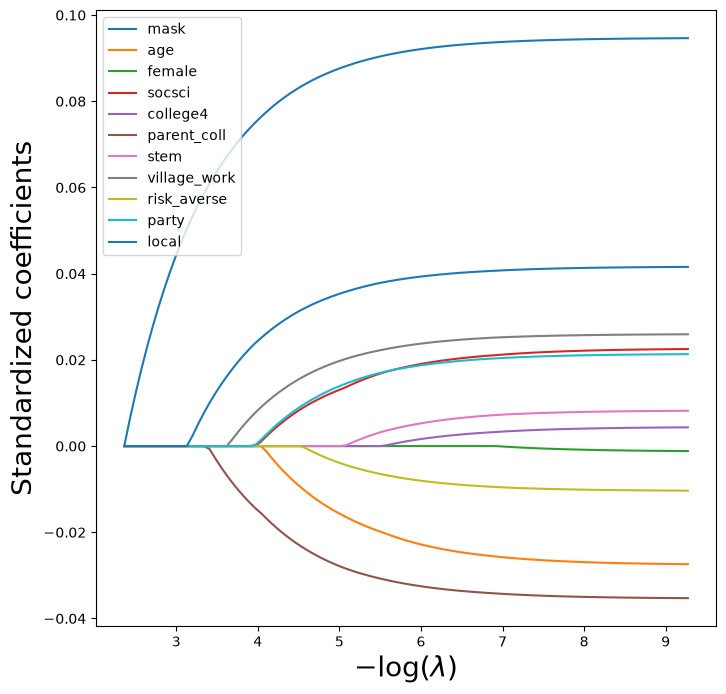

In [17]:
# Cell 17 — LASSO coefficient path
path_fig, ax = subplots(figsize=(8, 8))
soln_path_l.plot(ax=ax, legend=False)
ax.legend(loc='upper left')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20)

path_fig.savefig("figs/lasso_path_graph.pdf", bbox_inches="tight")

LASSO min CV MSE: 0.6286198843872794
Dropped variables: 3 / 11


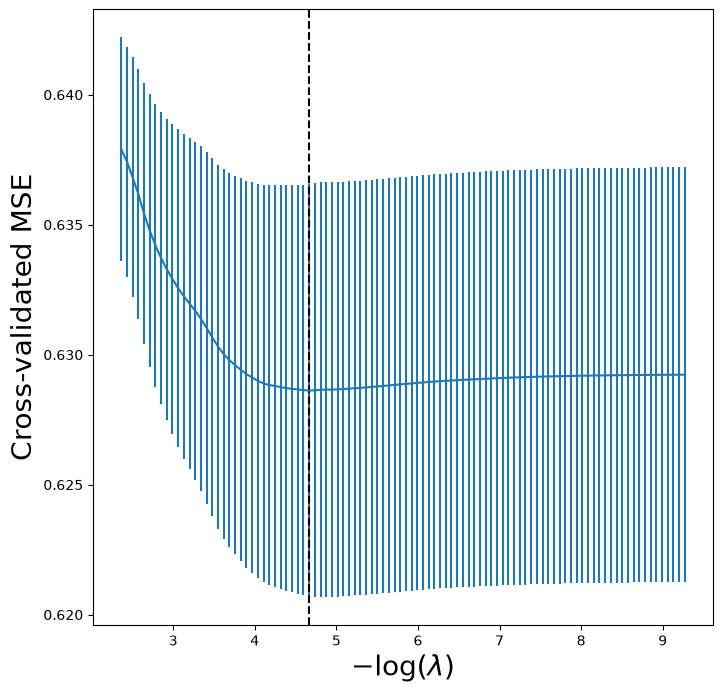

In [18]:
# Cell 18 — LASSO CV MSE
lassoCV_fig, ax = subplots(figsize=(8, 8))
ax.errorbar(-np.log(tuned_lasso.alphas_),
            tuned_lasso.mse_path_.mean(1),
            yerr=tuned_lasso.mse_path_.std(1) / np.sqrt(K))
ax.axvline(-np.log(tuned_lasso.alpha_), c='k', ls='--')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20)
lassoCV_fig.savefig("figs/lasso_cv_mse_graph.pdf", bbox_inches="tight")

lasso_min_mse = np.min(tuned_lasso.mse_path_.mean(1))
n_dropped = int((tuned_lasso.coef_ == 0).sum())
with open("tabs/cell17_lasso_mse_table.txt", "w") as f:
    f.write(f"LASSO min CV MSE = {lasso_min_mse}\n")
    f.write(f"Dropped variables = {n_dropped} / {len(D.columns)}\n")
print("LASSO min CV MSE:", lasso_min_mse)
print("Dropped variables:", n_dropped, "/", len(D.columns))

In [19]:
# Cell 19 — null model - ISLP 114
Xn = np.zeros((X.shape[0], 1))
cv_null = skm.cross_validate(skl.LinearRegression(), Xn, Y, cv=kfold,
                             scoring='neg_mean_squared_error')
null_mse = -cv_null['test_score'].mean()
with open("tabs/cell18_null_mse_table.txt", "w") as f:
    f.write(f"Null CV MSE = {null_mse}\n")
    
print("Null CV MSE:", null_mse)

Null CV MSE: 0.6380192932553083


In [20]:
# Cell 20 — OLS / Ridge / LASSO
FE_dum_direct = pd.get_dummies(d[FE[0]], prefix=FE[0], drop_first=True)
for c in FE[1:]:
    FE_dum_direct = pd.concat([FE_dum_direct, pd.get_dummies(d[c], prefix=c, drop_first=True)], axis=1)
FE_dum_direct = FE_dum_direct.astype(float)

X_direct = pd.concat([d[cols].astype(float).reset_index(drop=True),
                       FE_dum_direct.reset_index(drop=True)], axis=1)
Y_direct = d[Y_name].astype(float).values
mask_idx_direct = list(X_direct.columns).index(TREAT)
p = X_direct.shape[1] 

# --- OLS (NO FWL) ---
Xc_direct = sm.add_constant(X_direct)
ols_nofwl = OLS(Y_direct, Xc_direct).fit(cov_type="cluster", cov_kwds={"groups": d["unit"].values})
with open("tabs/ols_table_NO_FWL.txt", "w") as f:
    f.write(str(ols_nofwl.summary()))
print("=== OLS (NO FWL) ===")
print("mask coef:", ols_nofwl.params[TREAT], "| p-value:", ols_nofwl.pvalues[TREAT])

# --- Ridge (NO FWL) ---
scaler_direct = StandardScaler()
Xs_direct = scaler_direct.fit_transform(X_direct.values)
Yc_direct = Y_direct - Y_direct.mean()

ridgeCV_nofwl = skl.ElasticNetCV(alphas=lambdas, l1_ratio=0, cv=kfold).fit(Xs_direct, Yc_direct)
ridge_mask_nofwl = ridgeCV_nofwl.coef_[mask_idx_direct] / scaler_direct.scale_[mask_idx_direct]
with open("tabs/ridge_table_NO_FWL.txt", "w") as f:
    f.write(f"Ridge (NO FWL) best alpha = {ridgeCV_nofwl.alpha_}\n")
    f.write(f"Ridge (NO FWL) mask coef (raw units) = {ridge_mask_nofwl}\n")
print("=== Ridge (NO FWL) ===")
print("best alpha:", ridgeCV_nofwl.alpha_, "| mask coef (raw units):", ridge_mask_nofwl)

# --- LASSO (NO FWL) ---
lassoCV_nofwl = skl.ElasticNetCV(alphas=100, l1_ratio=1, cv=kfold).fit(Xs_direct, Yc_direct)
lasso_mask_nofwl = lassoCV_nofwl.coef_[mask_idx_direct] / scaler_direct.scale_[mask_idx_direct]
n_dropped_nofwl = int((lassoCV_nofwl.coef_ == 0).sum())
with open("tabs/lasso_table_NO_FWL.txt", "w") as f:
    f.write(f"LASSO (NO FWL) best alpha = {lassoCV_nofwl.alpha_}\n")
    f.write(f"LASSO (NO FWL) mask coef (raw units) = {lasso_mask_nofwl}\n")
    f.write(f"LASSO (NO FWL) dropped variables (incl. FE dummies) = {n_dropped_nofwl} / {len(X_direct.columns)}\n")
print("=== LASSO (NO FWL) ===")
print("best alpha:", lassoCV_nofwl.alpha_, "| mask coef (raw units):", lasso_mask_nofwl)
print("dropped variables:", n_dropped_nofwl, "/", len(X_direct.columns))

c:\Users\unite\anaconda3\envs\causalml\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 252, but rank is 239
  res = self.wald_test(


=== OLS (NO FWL) ===
mask coef: 0.21362586603299238 | p-value: 4.286798692638641e-09
=== Ridge (NO FWL) ===
best alpha: 0.6535626934532438 | mask coef (raw units): 0.12592509280021968
=== LASSO (NO FWL) ===
best alpha: 0.012675789162574263 | mask coef (raw units): 0.18983280535229188
dropped variables: 101 / 252


In [21]:
# Cell 21 — Appendix
mask_j_fwl = cols.index(TREAT)

comparison = pd.DataFrame({
    "Model": ["OLS", "Ridge", "LASSO"],
    "FWL-partialled": [
        ols_fe.params[TREAT],
        tuned_ridge.coef_[mask_j_fwl] / X_scale[mask_j_fwl],
        tuned_lasso.coef_[mask_j_fwl] / X_scale[mask_j_fwl],
    ],
    "FE-direct (NO FWL)": [
        ols_nofwl.params[TREAT],
        ridge_mask_nofwl,
        lasso_mask_nofwl,
    ],
})
comparison["Abs. difference"] = (comparison["FWL-partialled"] - comparison["FE-direct (NO FWL)"]).abs()

comparison.to_csv("tabs/fwl_vs_nofwl_comparison_table.csv", index=False)

latex_table = comparison.to_latex(index=False, float_format="%.4f",
    caption="Comparison of the mask coefficient under FWL-partialled vs. direct FE inclusion.",
    label="tab:fwl_robustness")
with open("tabs/fwl_vs_nofwl_comparison_table.tex", "w") as f:
    f.write(latex_table)

print(comparison)

   Model  FWL-partialled  FE-direct (NO FWL)  Abs. difference
0    OLS        0.213626            0.213626     1.609823e-15
1  Ridge        0.189091            0.125925     6.316613e-02
2  LASSO        0.191301            0.189833     1.467901e-03


In [22]:
# Cell 22 — ISLP 6
from sklearn.tree import (DecisionTreeRegressor as DTR,
                           plot_tree,
                           export_text)
from sklearn.ensemble import (RandomForestRegressor as RF,
                               GradientBoostingRegressor as GBR)

|--- cgcs_type_6.0 <= 0.50
|   |--- age <= 25.50
|   |   |--- mask <= 0.50
|   |   |   |--- value: [5.02]
|   |   |--- mask >  0.50
|   |   |   |--- value: [5.25]
|   |--- age >  25.50
|   |   |--- county_30.0 <= 0.50
|   |   |   |--- value: [5.33]
|   |   |--- county_30.0 >  0.50
|   |   |   |--- value: [2.00]
|--- cgcs_type_6.0 >  0.50
|   |--- county_168.0 <= 0.50
|   |   |--- county_132.0 <= 0.50
|   |   |   |--- value: [5.78]
|   |   |--- county_132.0 >  0.50
|   |   |   |--- value: [4.00]
|   |--- county_168.0 >  0.50
|   |   |--- value: [3.00]



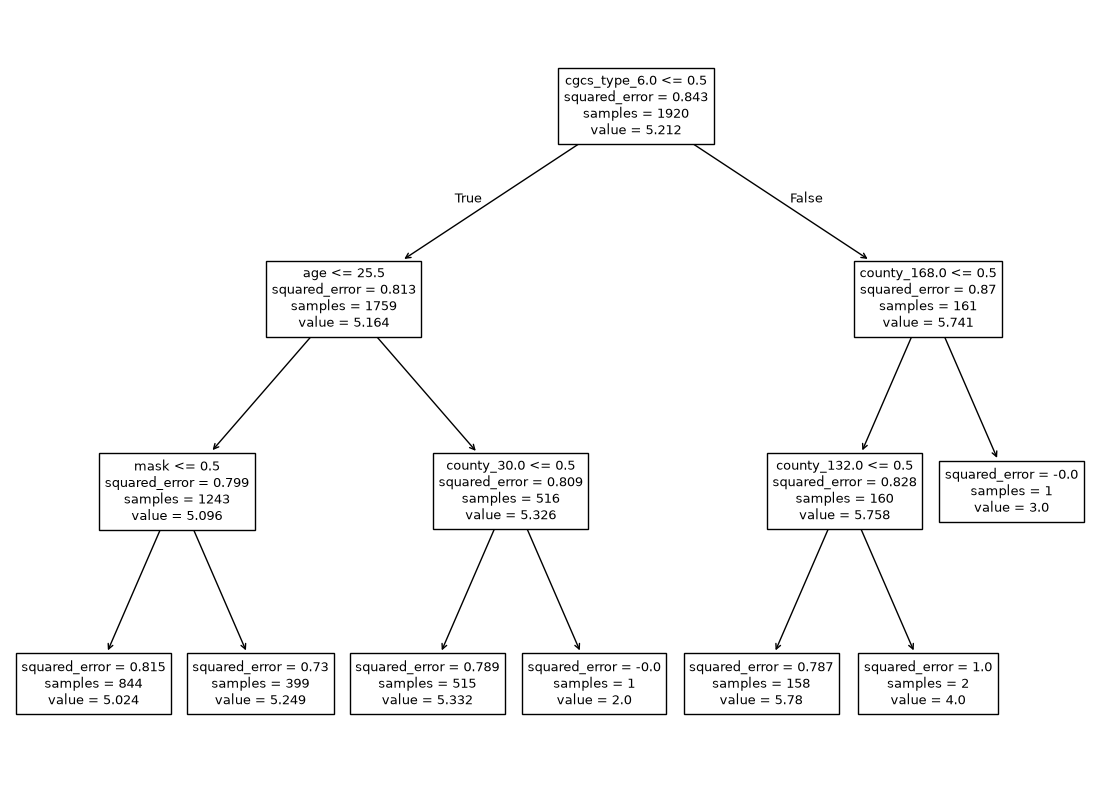

In [23]:
# Cell 23 — Regression Tree - ISLP 41/43
feature_names_tree = list(X_direct.columns)
Xt = np.asarray(X_direct)
Yt = Y_direct

(Xt_train, Xt_test, Yt_train, Yt_test) = skm.train_test_split(
    Xt, Yt, test_size=0.3, random_state=0)   

reg = DTR(max_depth=3, random_state=0)
reg.fit(Xt_train, Yt_train)
fig, ax = subplots(figsize=(14, 10))
plot_tree(reg, feature_names=feature_names_tree, ax=ax, fontsize=9)
fig.savefig("figs/tree_graph.pdf", bbox_inches="tight")

with open("tabs/tree_text_table.txt", "w") as f:
    f.write(export_text(reg, feature_names=feature_names_tree))
print(export_text(reg, feature_names=feature_names_tree))

Optimal leaves: 5
Test MSE (pruned tree): 0.778566065599928


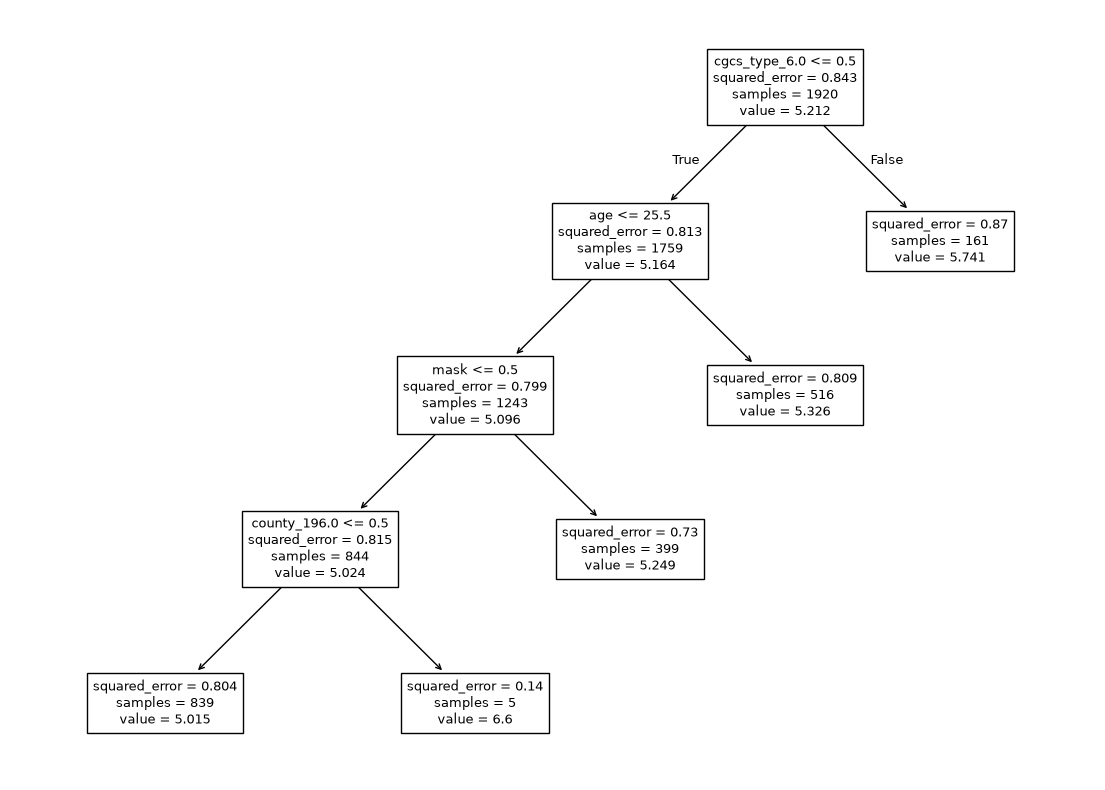

In [24]:
# Cell 24 — Cost-complexity pruning ISLP 48, 50
ccp_path = reg.cost_complexity_pruning_path(Xt_train, Yt_train)
kfold_tree = skm.KFold(5, shuffle=True, random_state=10)  
grid = skm.GridSearchCV(DTR(random_state=0), {'ccp_alpha': ccp_path.ccp_alphas},
                         refit=True, cv=kfold_tree, scoring='neg_mean_squared_error')
grid.fit(Xt_train, Yt_train)
best_tree = grid.best_estimator_

print("Optimal leaves:", best_tree.tree_.n_leaves)
print("Test MSE (pruned tree):", np.mean((Yt_test - best_tree.predict(Xt_test))**2))

fig, ax = subplots(figsize=(14, 10))
plot_tree(best_tree, feature_names=feature_names_tree, ax=ax, fontsize=9)
fig.savefig("figs/tree_pruned_graph.pdf", bbox_inches="tight")

In [25]:
# Cell 25 — Bagging (Max_depth = 50)
bag_param_grid = {'max_depth': [3, 5, 8, None]}
bag_grid = skm.GridSearchCV(RF(max_features=p, n_estimators=300, random_state=0),
                             bag_param_grid, cv=kfold_tree,
                             scoring='neg_mean_squared_error', n_jobs=-1)
bag_grid.fit(Xt_train, Yt_train)
best_bag = bag_grid.best_estimator_

bag_mse = np.mean((Yt_test - best_bag.predict(Xt_test))**2)
with open("tabs/bagging_tuned_table.txt", "w") as f:
    f.write(f"Bagging best max_depth = {bag_grid.best_params_}\n")
    f.write(f"Bagging (tuned) Test MSE = {bag_mse}\n")
    
print("Bagging best params:", bag_grid.best_params_)
print("Bagging (tuned) Test MSE:", bag_mse)

Bagging best params: {'max_depth': 8}
Bagging (tuned) Test MSE: 0.7494430350482166


In [26]:
# Cell 26 — Random Forest 
rf_param_grid = {
    'max_depth': [3, 5, 8, None],
    'max_features': [11, 30, 84, p],
}
rf_grid = skm.GridSearchCV(RF(n_estimators=300, random_state=0), rf_param_grid,
                            cv=kfold_tree, scoring='neg_mean_squared_error', n_jobs=-1)
rf_grid.fit(Xt_train, Yt_train)
best_rf = rf_grid.best_estimator_

rf_mse = np.mean((Yt_test - best_rf.predict(Xt_test))**2)
with open("tabs/rf_tuned_table.txt", "w") as f:
    f.write(f"RF best params = {rf_grid.best_params_}\n")
    f.write(f"RF (tuned) Test MSE = {rf_mse}\n")
print("RF best params:", rf_grid.best_params_)
print("RF (tuned) Test MSE:", rf_mse)

feature_imp = pd.DataFrame({'importance': best_rf.feature_importances_}, index=feature_names_tree)
top15 = feature_imp.sort_values(by='importance', ascending=False).head(15)
top15.to_csv("tabs/rf_importance_table.csv")
print(top15)

rf_rows = [f"{str(var).replace('_', chr(92)+'_')} & {row['importance']:.4f}"
           for var, row in top15.iterrows()]
save_latex_table("rf_importance_table.tex",
                  caption="Random Forest Variable Importance (Top 15)",
                  label="tab:rf_importance", col_spec="lr",
                  header="Variable & Importance", rows=rf_rows)

RF best params: {'max_depth': None, 'max_features': 11}
RF (tuned) Test MSE: 0.7482045089637058
               importance
age              0.091819
risk_averse      0.034500
socsci           0.031641
female           0.031507
stem             0.030615
parent_coll      0.030305
local            0.026687
year_2017        0.026676
mask             0.024609
cgcs_type_6.0    0.023978
party            0.021739
village_work     0.021317
college4         0.021233
cgcs_type_2.0    0.020927
cgcs_type_4.0    0.015586
Saved: tabs/rf_importance_table.tex


In [27]:
# Cell 27 — Boosting - ISLP 68,70

boost_param_grid = {
    'learning_rate': [0.001, 0.01, 0.1, 0.2],
    'max_depth': [1, 2, 3],
}
boost_grid = skm.GridSearchCV(GBR(n_estimators=1000, random_state=0), boost_param_grid,
                               cv=kfold_tree, scoring='neg_mean_squared_error', n_jobs=-1)
boost_grid.fit(Xt_train, Yt_train)
best_boost = boost_grid.best_estimator_

boost_mse = np.mean((Yt_test - best_boost.predict(Xt_test))**2)
with open("tabs/boosting_tuned_table.txt", "w") as f:
    f.write(f"Boosting best params = {boost_grid.best_params_}\n")
    f.write(f"Boosting (tuned) Test MSE = {boost_mse}\n")
print("Boosting best params:", boost_grid.best_params_)
print("Boosting (tuned) Test MSE:", boost_mse)

Boosting best params: {'learning_rate': 0.01, 'max_depth': 3}
Boosting (tuned) Test MSE: 0.7299919679974585


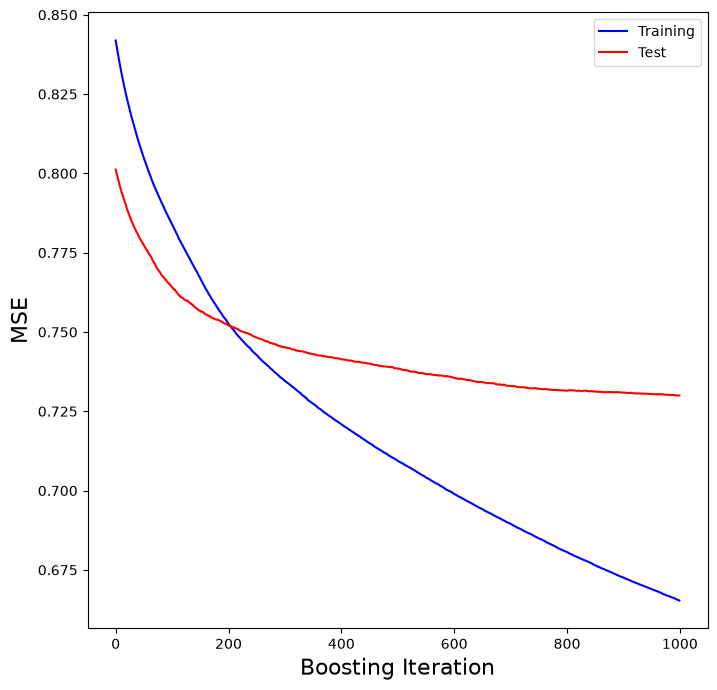

In [28]:
# Cell 28 — ISLP 70
test_error = np.zeros_like(best_boost.train_score_)
for idx, y_ in enumerate(best_boost.staged_predict(Xt_test)):
    test_error[idx] = np.mean((Yt_test - y_)**2)

plot_idx = np.arange(best_boost.train_score_.shape[0])
fig, ax = subplots(figsize=(8, 8))
ax.plot(plot_idx, best_boost.train_score_, 'b', label='Training')
ax.plot(plot_idx, test_error, 'r', label='Test')
ax.set_xlabel('Boosting Iteration', fontsize=16)
ax.set_ylabel('MSE', fontsize=16)
ax.legend()
fig.savefig("figs/boosting_graph.pdf", bbox_inches="tight")

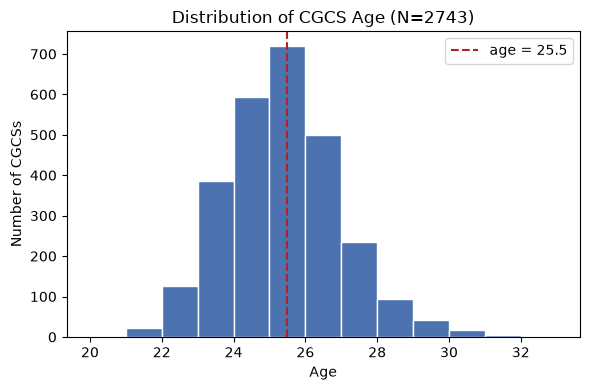

In [29]:
# Cell 29 — Summary Statistics Visualizations
import matplotlib.pyplot as plt

# Plot 1: Age distribution
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(d['age'], bins=range(20,34), edgecolor='white', color='#4C72B0')
ax.axvline(25.5, color='firebrick', linestyle='--', linewidth=1.5, label='age = 25.5')
ax.set_xlabel('Age')
ax.set_ylabel('Number of CGCSs')
ax.set_title('Distribution of CGCS Age (N={})'.format(len(d)))
ax.legend()
fig.tight_layout()
fig.savefig('figs/age_hist.pdf')
plt.show()

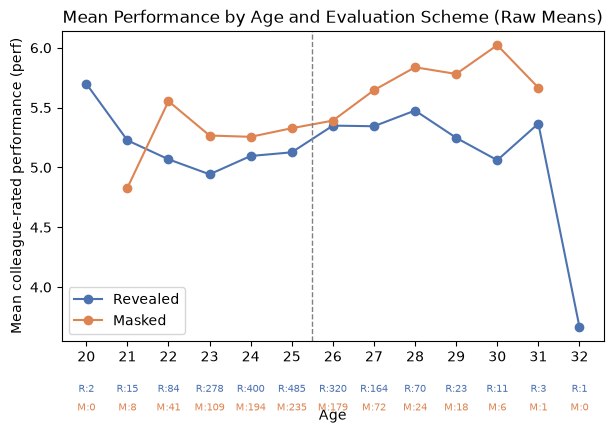

In [30]:
# Cell 30
import matplotlib.pyplot as plt

means = d.groupby(['age', TREAT])[Y_name].mean().reset_index()
counts = d.groupby(['age', TREAT]).size().unstack(fill_value=0)
counts.columns = ['revealed_n', 'masked_n']

fig, ax = plt.subplots(figsize=(7, 5))
for m, label, color in [(0, 'Revealed', '#4C72B0'), (1, 'Masked', '#DD8452')]:
    sub = means[means[TREAT] == m].sort_values('age')
    ax.plot(sub['age'], sub[Y_name], marker='o', label=label, color=color)
ax.axvline(25.5, color='gray', linestyle='--', linewidth=1)
ax.set_ylabel('Mean colleague-rated performance (perf)')
ax.set_title('Mean Performance by Age and Evaluation Scheme (Raw Means)')
ax.legend()

# N labels under each x-tick, stacked vertically (revealed on top, masked below)
ages = sorted(d['age'].unique())
ax.set_xticks(ages)
trans = ax.get_xaxis_transform()  # x in data coords, y in axes-fraction coords
for a in ages:
    r_n = int(counts.loc[a, 'revealed_n']) if a in counts.index else 0
    m_n = int(counts.loc[a, 'masked_n']) if a in counts.index else 0
    ax.text(a, -0.14, f"R:{r_n}", transform=trans, ha='center', va='top',
            fontsize=7, color='#4C72B0')
    ax.text(a, -0.20, f"M:{m_n}", transform=trans, ha='center', va='top',
            fontsize=7, color='#DD8452')

ax.set_xlabel('Age', labelpad=32)
fig.subplots_adjust(bottom=0.26)
fig.savefig('figs/perf_by_age_with_n.pdf')
plt.show()

In [31]:
# Cell 31 - Summary statistics table
summary_vars = [TREAT, Y_name] + KEY_COVS
summary = d[summary_vars].describe().T[['count','mean','std','min','50%','max']]
summary = summary.rename(columns={'50%':'median'})
print(summary.round(3))

summary.round(3).to_csv("tabs/summary_stats_table.csv")

summary_out = summary.reset_index().rename(columns={'index': 'Variable'})

summary_rows = [
    f"{row['Variable'].replace('_', chr(92)+'_')} & {row['count']:.3f} & {row['mean']:.3f} & "
    f"{row['std']:.3f} & {row['min']:.3f} & {row['median']:.3f} & {row['max']:.3f}"
    for _, row in summary_out.iterrows()
]
save_latex_table("summary_stats_table.tex",
                  caption=f"Summary Statistics of Key Variables (N={len(d)})",
                  label="tab:summary_stats", col_spec="lrrrrrr",
                  header="Variable & count & mean & std & min & median & max",
                  rows=summary_rows, resizebox="0.8\\textwidth")

               count    mean    std   min  median   max
mask          2743.0   0.323  0.468   0.0     0.0   1.0
perf          2743.0   5.232  0.911   2.0     5.0   7.0
age           2743.0  24.886  1.622  20.0    25.0  32.0
female        2743.0   0.618  0.486   0.0     1.0   1.0
socsci        2743.0   0.534  0.499   0.0     1.0   1.0
college4      2743.0   0.721  0.448   0.0     1.0   1.0
parent_coll   2743.0   0.290  0.454   0.0     0.0   1.0
stem          2743.0   0.346  0.476   0.0     0.0   1.0
village_work  2743.0   0.154  0.361   0.0     0.0   1.0
risk_averse   2743.0   0.474  0.499   0.0     0.0   1.0
party         2743.0   0.216  0.412   0.0     0.0   1.0
local         2743.0   0.678  0.467   0.0     1.0   1.0
Saved: tabs/summary_stats_table.tex


In [32]:
# Cell 32
import pandas as pd
from scipy import stats

att = pd.read_stata("data/Attrition_data.dta", convert_categoricals=False)

# T2_pool is the original treatment assignment (0=revealed, 1=masked),
# recorded for all 3,785 CGCSs originally randomized (unlike 'mask' in
# Main_data.dta, which only exists for the 2,854 who did not attrite).
revealed = att.loc[att['T2_pool'] == 0, 'attrite']
masked   = att.loc[att['T2_pool'] == 1, 'attrite']

t_stat, p_value = stats.ttest_ind(masked, revealed, equal_var=True)

print(f"Revealed attrition rate: {revealed.mean()*100:.1f}% (N={len(revealed)})")
print(f"Masked attrition rate:   {masked.mean()*100:.1f}% (N={len(masked)})")
print(f"t-statistic: {t_stat:.3f}, p-value: {p_value:.3f}")

att_rows = [
    f"Attrition rate & {revealed.mean()*100:.1f}\\% & {masked.mean()*100:.1f}\\% & {t_stat:.3f} & {p_value:.3f}",
    f"N & {len(revealed)} & {len(masked)} & & ",
]
save_latex_table("attrition_ttest_table.tex",
                  caption="Attrition Rate by Treatment Status (t-test)",
                  label="tab:attrition_ttest", col_spec="lrrrr",
                  header=" & Revealed & Masked & t-statistic & p-value", rows=att_rows)

Revealed attrition rate: 24.9% (N=2575)
Masked attrition rate:   23.9% (N=1210)
t-statistic: -0.647, p-value: 0.518
Saved: tabs/attrition_ttest_table.tex


In [33]:
# Cell 33 - Attrition logit (exogeneity / no differential attrition test)
import statsmodels.api as sm

att = pd.read_stata("data/Attrition_data.dta", convert_categoricals=False)

A = att['attrite']          # 1 = left sample before endline
T = att['T2_pool']          # 1 = masked

X = sm.add_constant(T)
attrition_logit = sm.Logit(A, X).fit(disp=0)
print(attrition_logit.summary())

coef = attrition_logit.params['T2_pool']
se   = attrition_logit.bse['T2_pool']
z    = attrition_logit.tvalues['T2_pool']
p    = attrition_logit.pvalues['T2_pool']

logit_rows = [f"mask & {coef:.4f} & {se:.4f} & {z:.3f} & {p:.3f}"]
save_latex_table("attrition_logit_table.tex",
                  caption="Logit Regression of Attrition on Treatment Status",
                  label="tab:attrition_logit", col_spec="lrrrr",
                  header=" & Coefficient & Std. Err. & z & p-value", rows=logit_rows)

                           Logit Regression Results                           
Dep. Variable:                attrite   No. Observations:                 3785
Model:                          Logit   Df Residuals:                     3783
Method:                           MLE   Df Model:                            1
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:               9.948e-05
Time:                        17:29:43   Log-Likelihood:                -2109.1
converged:                       True   LL-Null:                       -2109.3
Covariance Type:            nonrobust   LLR p-value:                    0.5171
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.1064      0.046    -24.263      0.000      -1.196      -1.017
T2_pool       -0.0526      0.081     -0.647      0.518      -0.212       0.107
Saved: tabs/attrition_logit_table.tex


In [34]:
# Cell 34
from scipy import stats

covs = ['age','female','socsci','college4','parent_coll','stem',
        'village_work','risk_averse','party','local']

rows = []
for c in covs:
    rev = d.loc[d[TREAT] == 0, c]
    msk = d.loc[d[TREAT] == 1, c]
    t, p = stats.ttest_ind(msk, rev, nan_policy='omit', equal_var=False)
    rows.append((c, rev.mean(), rev.std()/len(rev)**0.5,
                    msk.mean(), msk.std()/len(msk)**0.5, t, p))

balance = pd.DataFrame(rows, columns=['Variable','Revealed_mean','Revealed_se',
                                       'Masked_mean','Masked_se','t','p'])
balance.round(4).to_csv("tabs/balance_table.csv", index=False)
print(balance.round(3))

balance_rows = [
    f"{r['Variable'].replace('_', chr(92)+'_')} & {r['Revealed_mean']:.3f} & {r['Revealed_se']:.3f} & "
    f"{r['Masked_mean']:.3f} & {r['Masked_se']:.3f} & {r['t']:.3f} & {r['p']:.3f}"
    for _, r in balance.iterrows()
]
save_latex_table("balance_table.tex",
                  caption="Balance of Baseline Covariates by Treatment Status",
                  label="tab:balance", col_spec="lrrrrrr",
                  header="Variable & Revealed Mean & Revealed SE & Masked Mean & Masked SE & t & p",
                  rows=balance_rows, resizebox="\\textwidth")

       Variable  Revealed_mean  Revealed_se  Masked_mean  Masked_se      t  \
0           age      24.865999        0.038    24.927999      0.054  0.934   
1        female       0.616000        0.011     0.621000      0.016  0.243   
2        socsci       0.536000        0.012     0.529000      0.017 -0.361   
3      college4       0.721000        0.010     0.723000      0.015  0.096   
4   parent_coll       0.291000        0.011     0.286000      0.015 -0.277   
5          stem       0.348000        0.011     0.342000      0.016 -0.305   
6  village_work       0.156000        0.008     0.150000      0.012 -0.394   
7   risk_averse       0.471000        0.012     0.478000      0.017  0.322   
8         party       0.215000        0.010     0.219000      0.014  0.222   
9         local       0.680000        0.011     0.675000      0.016 -0.243   

       p  
0  0.351  
1  0.808  
2  0.718  
3  0.924  
4  0.782  
5  0.760  
6  0.694  
7  0.747  
8  0.825  
9  0.808  
Saved: tabs/balance_

In [ ]:
# Cell 35 - C - Missing data diagnostics (using existing `raw`)
covs_raw = ['mask','age','female','social_science','college_4','parent_college',
            'stem','village_work','risk_averse','party_member','local']
present = [c for c in covs_raw if c in raw.columns]

pre_drop = raw.groupby('cgvo_id')[present].mean()
print(pre_drop.shape)

pre_drop['M_age_missing'] = pre_drop['age'].isna().astype(int)
print(pre_drop.groupby('M_age_missing')[['female','social_science']].mean())

clean_covs = [c for c in ['mask','college_4','parent_college','stem','village_work',
                           'risk_averse','party_member','local'] if c in pre_drop.columns]
sub = pre_drop.dropna(subset=clean_covs)
X = sm.add_constant(sub[clean_covs])
mar_logit = sm.Logit(sub['M_age_missing'], X).fit(disp=0)
print(mar_logit.summary())
print('Joint LR p-value:', mar_logit.llr_pvalue)

mar_rows = [
    f"{v.replace('_', chr(92)+'_')} & {mar_logit.params[v]:.4f} & {mar_logit.bse[v]:.4f} & "
    f"{mar_logit.tvalues[v]:.3f} & {mar_logit.pvalues[v]:.3f}"
    for v in clean_covs
]
save_latex_table("mar_check_table.tex",
                  caption="Logit Regression of Missing-Age Indicator on Baseline Covariates "
                          "(Excluding Female, Social Science)",
                  label="tab:mar_check", col_spec="lrrrr",
                  header=" & Coefficient & Std. Err. & z & p-value", rows=mar_rows)

(2854, 11)
                 female  social_science
M_age_missing                          
0              0.617851        0.533698
1              0.000000        1.000000
                           Logit Regression Results                           
Dep. Variable:          M_age_missing   No. Observations:                 2854
Model:                          Logit   Df Residuals:                     2845
Method:                           MLE   Df Model:                            8
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:                 0.01092
Time:                        17:29:43   Log-Likelihood:                -457.74
converged:                       True   LL-Null:                       -462.79
Covariance Type:            nonrobust   LLR p-value:                    0.2579
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -3.6082      

In [36]:
# Cell 36 - D - Propensity score diagnostics
att = pd.read_stata("data/Attrition_data.dta", convert_categoricals=False)
att['female'] = (att['gender1']=='female').astype(int)
covs2 = ['female','social_science','college_4','parent_college','stem','village_work','risk_averse','party_member','age']

X_T = sm.add_constant(att[covs2])
m_T = sm.Logit(att['T2_pool'], X_T).fit(disp=0)
print('P(T|X) joint LR p-value:', m_T.llr_pvalue)

X_A = sm.add_constant(att[covs2 + ['T2_pool']])
m_A = sm.Logit(att['attrite'], X_A).fit(disp=0)
print('P(A|X) joint LR p-value:', m_A.llr_pvalue)

prop_rows = [
    f"P(T$=$mask $\\mid$ X) & {m_T.llr_pvalue:.3f} & {m_T.prsquared:.4f}",
    f"P(A$=$attrite $\\mid$ X, T) & {m_A.llr_pvalue:.4f} & {m_A.prsquared:.4f}",
]
save_latex_table("propensity_joint_table.tex",
                  caption="Joint Predictiveness of Baseline Covariates for Treatment and Attrition",
                  label="tab:propensity_joint", col_spec="lrr",
                  header=" & Joint LR $\\chi^2$ p-value & Pseudo $R^2$", rows=prop_rows)

P(T|X) joint LR p-value: 0.14349407128203784
P(A|X) joint LR p-value: 3.218253880356164e-05
Saved: tabs/propensity_joint_table.tex


In [37]:
# Cell 37 - DAG
import networkx as nx
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

In [ ]:
# Cell 38 - DAG1
dag1 = nx.DiGraph()
dag1.add_edges_from([
    ("mask", "perf"),
    ("baseline_X", "perf"),
])

pos1 = {
    "mask": (1.3, 0),
    "perf": (2.6, 0),
    "baseline_X": (1.95, 1.0),
}
colors1 = {
    "mask": "#4c9be8", "perf": "#f2a65a",
    "baseline_X": "#a8d5a2",
}

fig, ax = plt.subplots(figsize=(5.5, 3))
nx.draw_networkx_nodes(dag1, pos1, ax=ax, node_size=2200,
                        node_color=[colors1[n] for n in dag1.nodes()],
                        edgecolors="#333333", linewidths=0.8)
nx.draw_networkx_labels(dag1, pos1, ax=ax, font_size=9)
nx.draw_networkx_edges(dag1, pos1, ax=ax, arrowsize=14, edge_color="#555555",
                        width=1.4, node_size=2200)
ax.set_title("DAG 1: The Experiment (No Confounding)", fontsize=11)
ax.axis("off")
ax.margins(0.15)
plt.tight_layout()
plt.savefig("figs/dag1_ideal.pdf", dpi=150)
plt.close(fig)
print("saved figs/dag1_ideal.pdf\n")

[DAG 1] is DAG? True
saved figs/dag1_ideal.pdf



In [ ]:
# Cell 39 - DAG2
dag2 = nx.DiGraph()
dag2.add_edges_from([
    ("age", "mask"),
    ("mask", "perf"),
    ("baseline_X", "perf"),
    ("age", "perf"),
])

pos2 = {
    "mask": (1.3, 0),
    "perf": (2.6, 0),
    "baseline_X": (1.95, 1.0),
    "age": (1.3, 1.3),
}
colors2 = {
    "mask": "#4c9be8", "perf": "#f2a65a",
    "baseline_X": "#a8d5a2", "age": "#f4a6a6",
}

backdoor_edges = {("age", "mask"), ("age", "perf")}
edge_list = list(dag2.edges())
edge_colors = ["#d62728" if e in backdoor_edges else "#555555" for e in edge_list]
edge_widths = [2.0 if e in backdoor_edges else 1.4 for e in edge_list]

fig, ax = plt.subplots(figsize=(5.5, 3.3))
nx.draw_networkx_nodes(dag2, pos2, ax=ax, node_size=2200,
                        node_color=[colors2[n] for n in dag2.nodes()],
                        edgecolors="#333333", linewidths=0.8)
nx.draw_networkx_labels(dag2, pos2, ax=ax, font_size=9)
nx.draw_networkx_edges(dag2, pos2, ax=ax, edgelist=edge_list, arrowsize=14,
                        edge_color=edge_colors, width=edge_widths,
                        node_size=2200)
ax.set_title("DAG 2: The Biased Sample (S = age)", fontsize=11)
ax.axis("off")
ax.margins(0.15)
plt.tight_layout()
plt.savefig("figs/dag2_biased_sample.pdf", dpi=150)
plt.close(fig)
print("saved figs/dag2_biased_sample.pdf")

[DAG 2] is DAG? True
saved figs/dag2_biased_sample.pdf


In [ ]:
# Cell 40 - DAG 3
dag3 = nx.DiGraph()
dag3.add_edges_from([
    ("mask", "perf"),          # direct effect
    ("mask", "improve_i"),     # mask -> mediator
    ("improve_i", "perf"),     # mediator -> outcome
    ("baseline_X", "perf"),
])

pos3 = {
    "mask": (0, 0),
    "improve_i": (1.3, 1.0),
    "perf": (2.6, 0),
    "baseline_X": (1.95, -1.0),
}
colors3 = {
    "mask": "#4c9be8", "improve_i": "#c9a0e8", "perf": "#f2a65a",
    "baseline_X": "#a8d5a2",
}

mediator_edges = {("mask", "improve_i"), ("improve_i", "perf")}
edge_list = list(dag3.edges())
edge_colors = ["#8e44ad" if e in mediator_edges else "#555555" for e in edge_list]
edge_widths = [2.0 if e in mediator_edges else 1.4 for e in edge_list]

fig, ax = plt.subplots(figsize=(5.5, 3.3))
nx.draw_networkx_nodes(dag3, pos3, ax=ax, node_size=2200,
                        node_color=[colors3[n] for n in dag3.nodes()],
                        edgecolors="#333333", linewidths=0.8)
nx.draw_networkx_labels(dag3, pos3, ax=ax, font_size=9)
nx.draw_networkx_edges(dag3, pos3, ax=ax, edgelist=edge_list, arrowsize=14,
                        edge_color=edge_colors, width=edge_widths,
                        node_size=2200)
ax.set_title("DAG 3: Mediator (improve_i)", fontsize=11)
ax.axis("off")
ax.margins(0.15)
plt.tight_layout()
plt.savefig("figs/dag3_mediator.pdf", dpi=150)
plt.close(fig)
print("saved figs/dag3_mediator.pdf")

[DAG 3] is DAG? True
saved figs/dag3_mediator.pdf


In [41]:
# Cell 41 — Balance Plot
raw = pd.read_stata("data/Main_data.dta", convert_categoricals=False)

first = ["mask", "county", "type_dummy", "year", "unit", "age", "female", "social_science",
         "college_4", "parent_college", "stem", "village_work", "risk_averse",
         "party_member", "local"]
d = raw.groupby("cgvo_id").agg({"cgvo_relative_performance": "mean",
                                **{c: "first" for c in first}}).reset_index()
d = d.rename(columns={"cgvo_relative_performance": "perf", "type_dummy": "cgcs_type",
                      "social_science": "socsci", "college_4": "college4",
                      "parent_college": "parent_coll", "party_member": "party"})

TREAT = "mask"
KEY_COVS = ["age", "female", "socsci", "college4", "parent_coll", "stem",
            "village_work", "risk_averse", "party", "local"]

d = d.dropna(subset=[TREAT] + KEY_COVS).copy()

rows = []
for c in KEY_COVS:
    treated = d.loc[d[TREAT] == 1, c]
    control = d.loc[d[TREAT] == 0, c]
    diff = treated.mean() - control.mean()
    pooled_sd = np.sqrt((treated.var(ddof=1) + control.var(ddof=1)) / 2)
    std_diff = diff / pooled_sd
    se_diff = np.sqrt(treated.var(ddof=1)/len(treated) + control.var(ddof=1)/len(control))
    t_stat, p_val = stats.ttest_ind(treated, control, equal_var=False)
    std_se = se_diff / pooled_sd
    rows.append({"covariate": c, "std_diff": std_diff, "std_se": std_se,
                 "ci_low": std_diff - 1.96*std_se, "ci_high": std_diff + 1.96*std_se,
                 "p": p_val})

bal = pd.DataFrame(rows).sort_values("covariate")
print(bal.to_string(index=False))

label_map = {"age": "age", "female": "female", "socsci": "socsci", "college4": "college4",
             "parent_coll": "parent\\_coll", "stem": "stem", "village_work": "village\\_work",
             "risk_averse": "risk\\_averse", "party": "party", "local": "local"}

order = ["age", "female", "socsci", "college4", "parent_coll", "stem",
         "village_work", "risk_averse", "party", "local"]
bal = bal.set_index("covariate").loc[order].reset_index()

fig, ax = plt.subplots(figsize=(6, 5))
y_pos = np.arange(len(bal))[::-1]
ax.errorbar(bal["std_diff"], y_pos,
            xerr=[bal["std_diff"]-bal["ci_low"], bal["ci_high"]-bal["std_diff"]],
            fmt='o', color='black', ecolor='gray', capsize=3)
ax.axvline(0, color='red', linestyle='--', linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels([label_map[c] for c in bal["covariate"]])
ax.set_xlabel("Standardized mean difference (masked - revealed)")
ax.set_title("Balance Plot: Baseline Covariates")
fig.tight_layout()
fig.savefig("figs/balance_plot.pdf", bbox_inches="tight")
print("Saved figs/balance_plot.pdf")

C:\Users\unite\AppData\Local\Temp\ipykernel_6664\2637588459.py:2: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  raw = pd.read_stata("data/Main_data.dta", convert_categoricals=False)


   covariate  std_diff   std_se    ci_low  ci_high        p
         age  0.036920 0.040693 -0.042839 0.116679 0.364385
    college4  0.003246 0.040802 -0.076726 0.083219 0.936596
      female  0.010169 0.040796 -0.069791 0.090129 0.803189
       local -0.010677 0.040843 -0.090730 0.069376 0.793810
 parent_coll -0.010620 0.040778 -0.090545 0.069305 0.794560
       party  0.009626 0.040862 -0.070463 0.089715 0.813789
 risk_averse  0.014172 0.040819 -0.065834 0.094177 0.728500
      socsci -0.014648 0.040821 -0.094657 0.065360 0.719752
        stem -0.011668 0.040786 -0.091610 0.068273 0.774848
village_work -0.017044 0.040695 -0.096807 0.062719 0.675397
Saved figs/balance_plot.pdf
